#EXPLORATORY DATA ANALYSIS

#BACC TOAMASINA 2023

##I - Introduction
>Dans le cadre de cette analyse, nous explorons les données des résultats du baccalauréat 2023 TOAMASINA, comprenant des informations telles que le numéro d'identification, le nom, la série, la mention, le centre d'examen, et l'établissement. L'objectif est de conduire une Analyse Exploratoire de Données (AED) pour identifier des tendances clés et des corrélations, fournissant ainsi des insights approfondis sur les performances des étudiants. Cette démarche vise à mieux comprendre le paysage éducatif en mettant en lumière des aspects cruciaux liés aux résultats du baccalauréat.
###Variable cible (target): "Mention"
Dans cette analyse exploratoire des résultats du baccalauréat, notre principal objectif est d'explorer la distribution des mentions (Passable, Assez bien, Bien, Très bien) afin de comprendre la performance des étudiants dans différentes séries, centres d'examen, et établissements. Cette approche nous permettra d'identifier des tendances significatives et de gain d'informations précieuses sur les facteurs influant sur les résultats du baccalauréat.

##II - Importation des Modules et du Jeu de Données
>Dans cette section, nous procédons à l'importation de tous les modules et bibliothèques nécessaires, ainsi que du jeu de données que nous explorerons par la suite.

In [ ]:
nltk.download('punkt')

[nltk_data] Downloading package punkt to /home/rojo/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


True

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import associations as assoc
import re
from wordcloud import WordCloud
from collections import Counter
from collections.abc import Mapping
from scipy.stats import chi2_contingency
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk import FreqDist
from tqdm import trange
import string
import warnings
sns.set_style('whitegrid')

In [ ]:
!gdown https://drive.google.com/u/0/uc?id=1-86lMJZ94mC5t2K5kG81wsm3LNGT78tW

Downloading...
From: https://drive.google.com/u/0/uc?id=1-86lMJZ94mC5t2K5kG81wsm3LNGT78tW
To: /content/bacc_toamasina2023.csv
100% 1.76M/1.76M [00:00<00:00, 147MB/s]


In [ ]:
data_bacc = pd.read_csv('./bacc_toamasina2023.csv')
data = data_bacc.copy()
data.head()

,Numero,Nom,Prenoms,Serie,Mention,Centre,Etablissement
0,142 0000,ANDRIANANTENAINA,Rija Evarist,A1,Passable,TOAMASINA I,Lycée Foulpointe
1,142 0001,NALAHATRA,Tahina Francice,A1,Passable,TOAMASINA I,Lycée Foulpointe
2,142 0002,RAJOSOA,Eugene Whilly,A1,Passable,TOAMASINA I,Lycée Foulpointe
3,142 0003,RAMANOELINA,Zinolà,A1,Passable,TOAMASINA I,Lycée Foulpointe
4,142 0004,RANDRIAMANANTENA,Jacques Marco,A1,Passable,TOAMASINA I,Lycée Foulpointe


##III - Exploration et assimilation du jeu des données.
>Dans la phase d'exploration approfondie et d'assimilation des données, nous plongeons au cœur du dataset, identifiant les caractéristiques clés et analysant leur distribution. Cette étape fondamentale jettera les bases pour une visualisation significative des tendances émergentes.
###1. Analyse de forme

In [ ]:
data.shape

(19879, 7)

- **Lignes :** 19879
- **Colonnes :** 7
- **Types de variables :**
    - Numero : Variable catégorielle (probablement identifiant unique).

    - Nom : Variable catégorielle (nom de l'étudiant).

    - Prenoms : Variable catégorielle (prénoms de l'étudiant).

    - Serie : Variable catégorielle (série d'examen).

    - Mention : Variable ordinale (avec des mentions ordonnées: "Passable", "Bien", "Très bien").

    - Centre : Variable catégorielle (centre d'examen).

    - Etablissement : Variable catégorielle (établissement scolaire).

- **Analyse des valeurs manquantes :**

In [ ]:
data.isnull().sum()

Numero             0
Nom                0
Prenoms          708
Serie              0
Mention            0
Centre             0
Etablissement      0
dtype: int64


>La colonne 'Prenoms' présente 708 valeurs manquantes, suggérant qu'en concaténant 'Nom' et 'Prenoms' pour créer une colonne combinée, on pourrait potentiellement éviter ces valeurs manquantes.

In [ ]:
data['Prenoms'] = data['Prenoms'].fillna("")
data['Nom et Prenoms'] = pd.concat([data['Nom'], data['Prenoms'].astype(str)], axis=1).apply(lambda x: ' '.join(x), axis=1)
data = data.drop(['Nom', 'Prenoms'], axis=1)
derniere_colonne = data.pop('Nom et Prenoms')
data.insert(1, 'Nom et Prenoms', derniere_colonne)
data

,Numero,Nom et Prenoms,Serie,Mention,Centre,Etablissement
0,142 0000,ANDRIANANTENAINA Rija Evarist,A1,Passable,TOAMASINA I,Lycée Foulpointe
1,142 0001,NALAHATRA Tahina Francice,A1,Passable,TOAMASINA I,Lycée Foulpointe
2,142 0002,RAJOSOA Eugene Whilly,A1,Passable,TOAMASINA I,Lycée Foulpointe
3,142 0003,RAMANOELINA Zinolà,A1,Passable,TOAMASINA I,Lycée Foulpointe
4,142 0004,RANDRIAMANANTENA Jacques Marco,A1,Passable,TOAMASINA I,Lycée Foulpointe
...,...,...,...,...,...,...
19874,956 0170,SOAVELO Marie Francelette,TTER,Passable,FENERIVE-EST,LTP Technologique Fénérive-Est
19875,956 0171,RAMANAMPISOA VOLOLONIAINA Lovasoa Charlotte,TTER,Assez bien,FENERIVE-EST,LTP Technologique Fénérive-Est
19876,956 0174,MALINKOURATSI Jeudinot Franki,TTER,Passable,FENERIVE-EST,LTP Technologique Fénérive-Est
19877,956 0176,IGNARAKA José Christalino,TTER,Passable,FENERIVE-EST,LTP Technologique Fénérive-Est


>Eh bien, le premier problème est résolu.

- **Analyse des valeurs dupliqués:**

In [ ]:
data[data.duplicated(['Nom et Prenoms'])]

,Numero,Nom et Prenoms,Serie,Mention,Centre,Etablissement
711,142 1414,MARCELLIN,A1,Passable,SOANIERANA IVONGO,Lycée Privé FAP School SOANERANA IVONGO
2861,270 3464,RASOANIRINA Carine,A2,Passable,TOAMASINA I,Candidat libre Général Toamasina I
6633,270 9681,FERLANDO,A2,Passable,FENERIVE-EST,Lycée Ampasina Maningory
7134,271 0733,RONALDINO,A2,Passable,FENERIVE-EST,Lycée Privé Institution Moderne et Cybernetique
7422,271 1424,SANDRA,A2,Passable,FENERIVE-EST,Candidat Libre Général Fénérive Est
...,...,...,...,...,...,...
18980,386 2468,RONALDO,S,Passable,MAROANTSETRA,Lycée Maroantsetra
19324,736 0288,FRANCISCO,TAMB,Passable,MAROANTSETRA,LT Professionnel Maroantsetra
19537,616 0102,FREDERIC,TMA,Passable,TOAMASINA I,LT Professionnel Toamasina
19617,576 0043,FREDO,TMEL,Assez bien,TOAMASINA I,LT Professionnel Toamasina


>Malgré la similitude des noms et prénoms, les individus correspondants dans le jeu de données présentent des différences significatives

## 2. Analyse de fond
- **Statistiques descriptives :**

In [ ]:
data.describe()

,Numero,Nom et Prenoms,Serie,Mention,Centre,Etablissement
count,19879,19879,19879,19879,19879,19879
unique,19879,19800,24,4,22,275
top,142 0000,FRANCISCO,A2,Passable,TOAMASINA I,Lycée Jacques Rabemananjara
freq,1,6,11670,16137,4817,605



>Les statistiques récapitulatives indiquent que le jeu de données sur les résultats du baccalauréat comporte 19879 entrées. Certaines colonnes, comme 'Prenoms', présentent des valeurs manquantes. La diversité des données est mise en évidence par le nombre d'entrées uniques dans chaque colonne. Les valeurs les plus fréquentes dans certaines colonnes, telles que la série 'A2' et la mention 'Passable', suggèrent des tendances significatives.


- **Visualisation des données :**
    - Analyse univariable

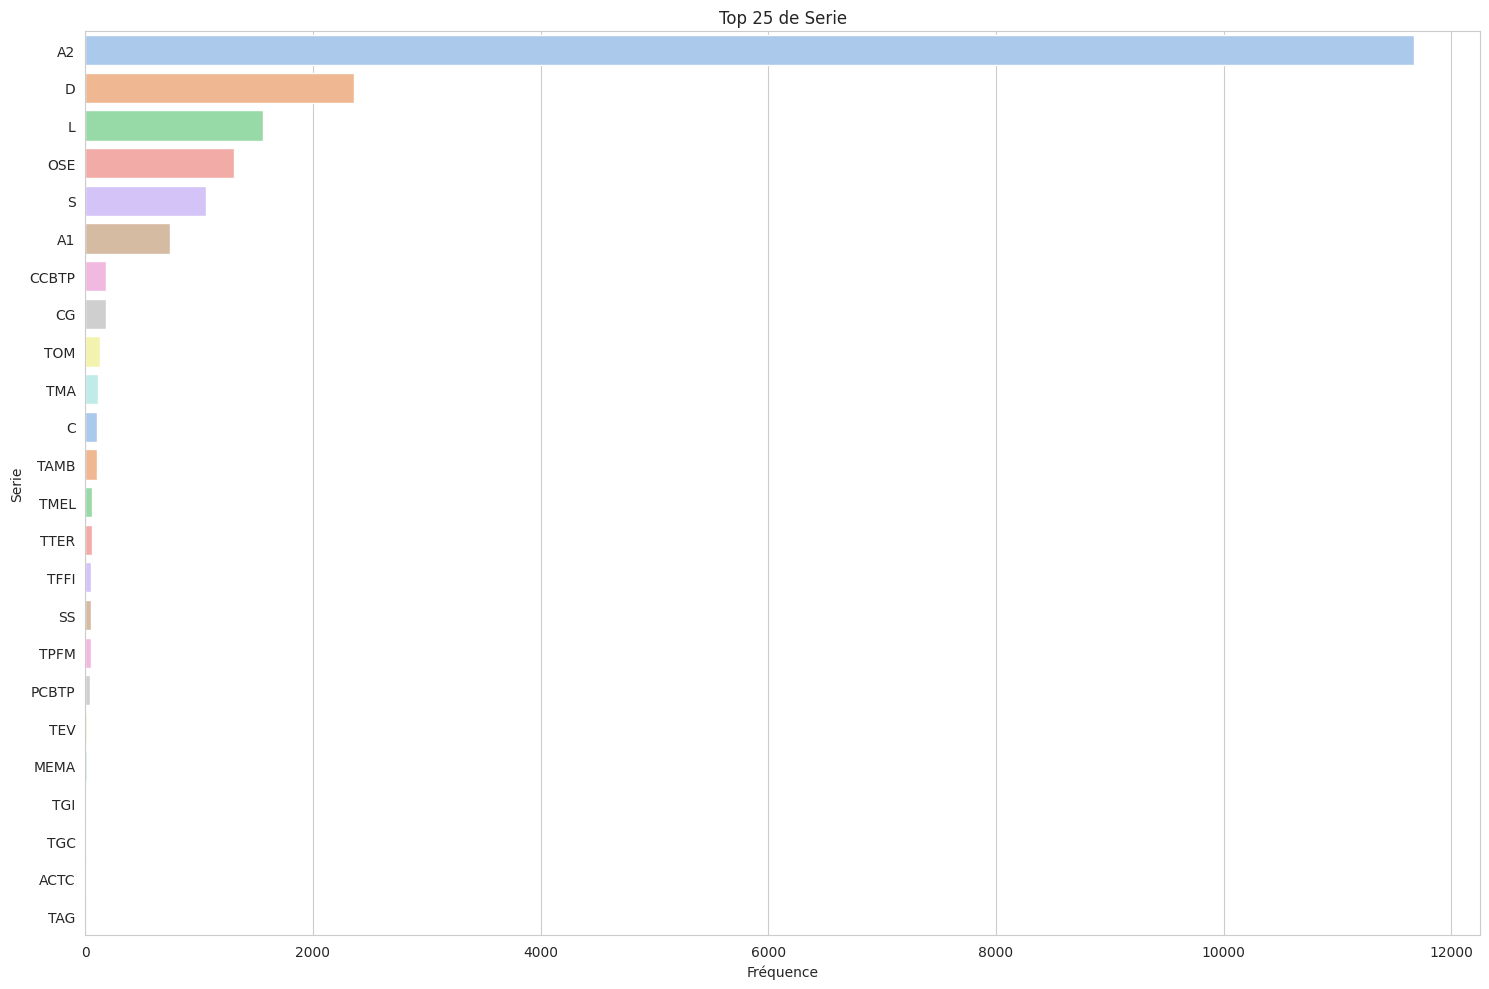

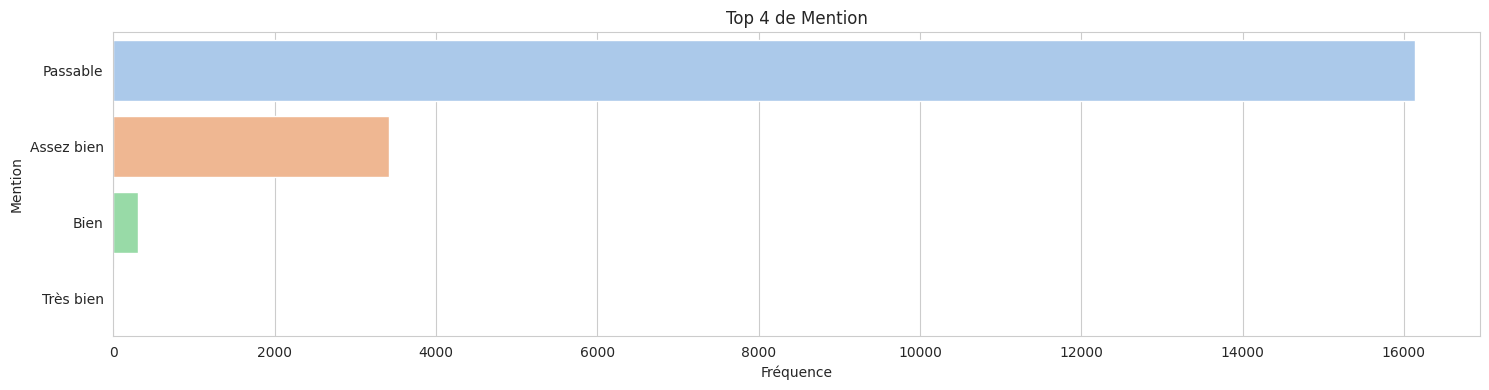

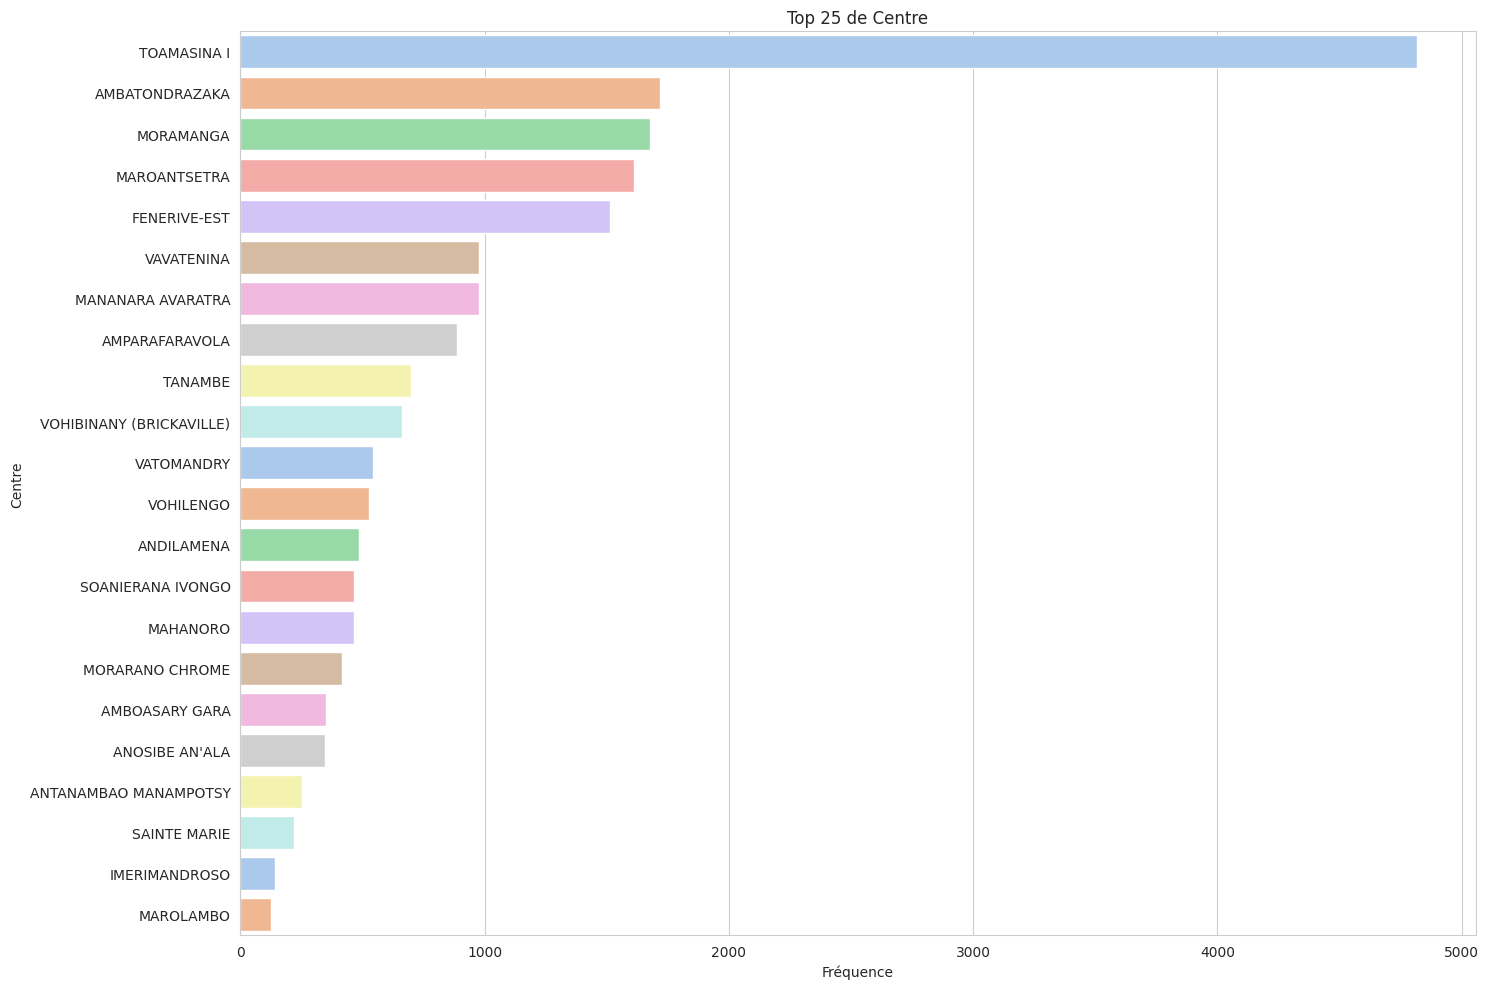

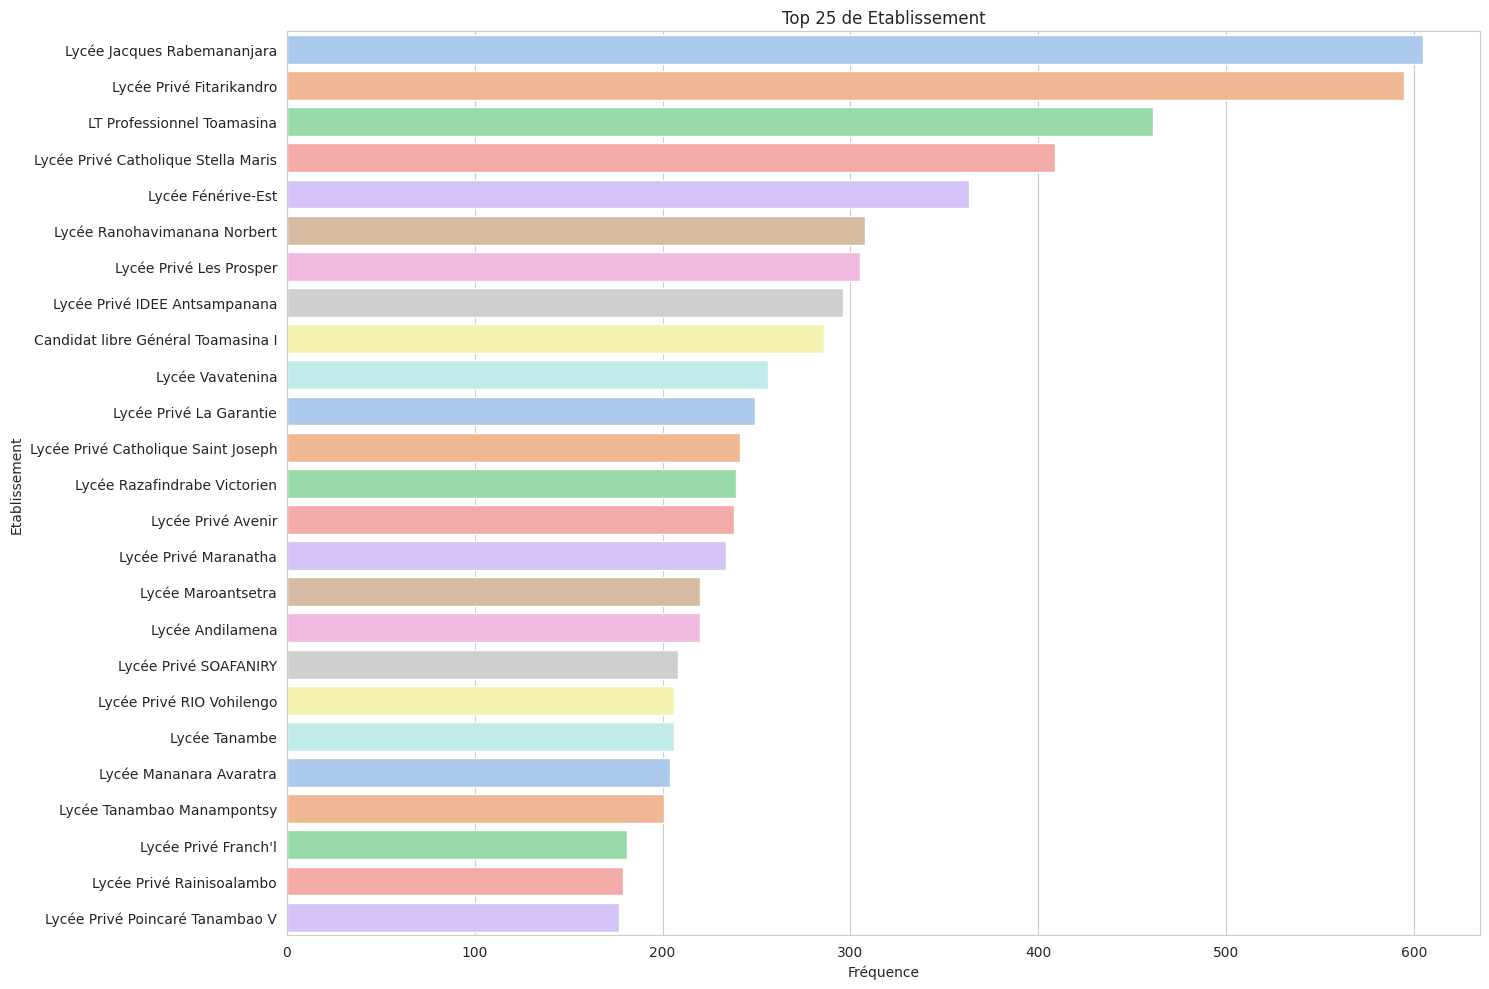

In [ ]:
warnings.filterwarnings("ignore", category=UserWarning)

for col in data.columns:
    if col != 'Numero' and col != 'Nom et Prenoms':
        size = data[col].nunique()
        top = data[col].nunique()
        if size > 10:
            size = 10
            top = 25
        plt.figure(figsize=(15, size))
        sns.countplot(y=col, data=data, palette='pastel', order=data[col].value_counts().index[:25])
        plt.title(f'Top {top} de {col}')
        plt.xlabel('Fréquence')
        plt.ylabel(col)
        plt.tight_layout()
        plt.show()
        print('\n')

> - Graphe 1:

La liste indique le nombre d'étudiants répartis dans différentes séries, avec A2 comptant le plus d'étudiants (11670), suivi de D (2358), et d'autres séries avec des effectifs décroissants jusqu'à une seule occurrence pour TAG.
> - Graphe 2:

Les résultats détaillent la fréquence des mentions obtenues par les étudiants, avec une prédominance de la mention "Passable" (16137), suivie d'"Assez bien" (3416), et des occurrences moins fréquentes pour les mentions "Bien" (311) et "Très bien" (15).
> - Graphe 3:

Les étudiants sont répartis dans divers centres d'examen, TOAMASINA I enregistrant le plus grand nombre (4817), suivi d'AMBATONDRAZAKA (1717), MORAMANGA (1676), et ainsi de suite. Cette liste illustre la diversité des centres et l'ampleur de la participation des étudiants.
> - Graphe 4:

Les étudiants sont affiliés à divers établissements scolaires, le Lycée Jacques Rabemananjara enregistrant le plus grand nombre (605), suivi du Lycée Privé Fitarikandro (595), et ainsi de suite. Ces données mettent en lumière la variété des établissements et l'engagement des étudiants dans chacun d'eux.

- ** **
    
    - Analyse Bivariable

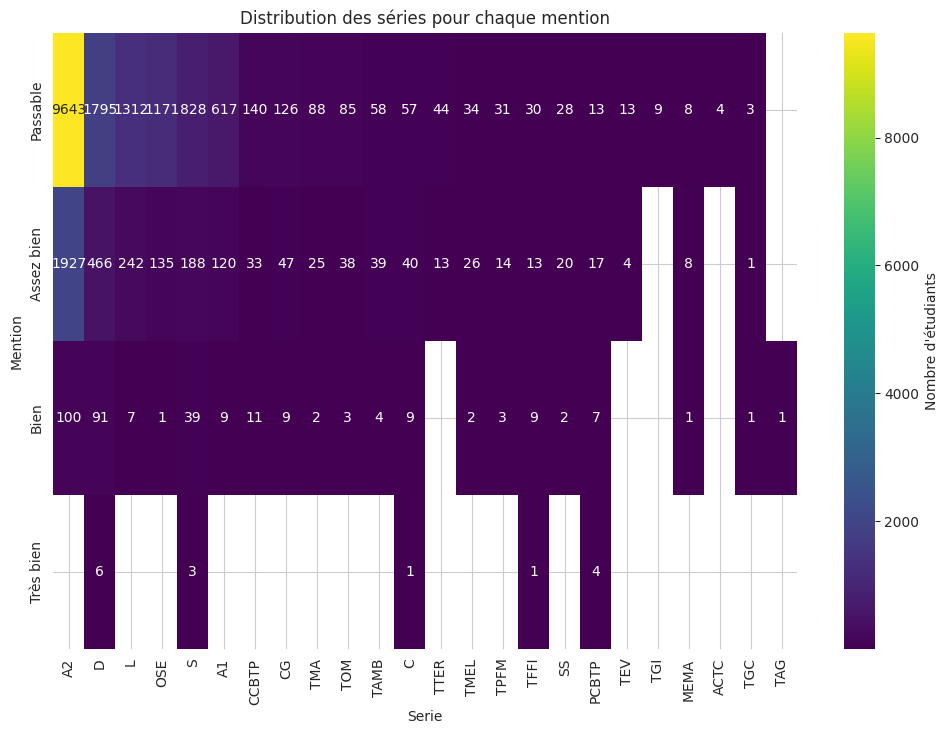

In [ ]:
mentions = data["Mention"].unique()
serie_mention_counts = []

for mention in mentions:
    subset_data = data[data["Mention"] == mention]
    serie_counts = subset_data["Serie"].value_counts()
    serie_mention_counts.append(serie_counts)

heatmap_data = pd.DataFrame(serie_mention_counts, index=mentions)

plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, annot=True, cmap="viridis", fmt="g", cbar_kws={'label': 'Nombre d\'étudiants'})
plt.xlabel("Serie")
plt.ylabel("Mention")
plt.title("Distribution des séries pour chaque mention")
plt.show()


>Le tableau représente le nombre d'étudiants dans chaque série d'examen, classés par mention (Passable, Assez bien, Bien, Très bien). Par exemple, dans la série "A2", il y a 9643 étudiants classés "Passable", 1927 étudiants classés "Assez bien", 100 étudiants classés "Bien", et aucun étudiant classé "Très bien". Les chiffres fournissent une répartition détaillée des performances des étudiants dans chaque série selon les différentes mentions.

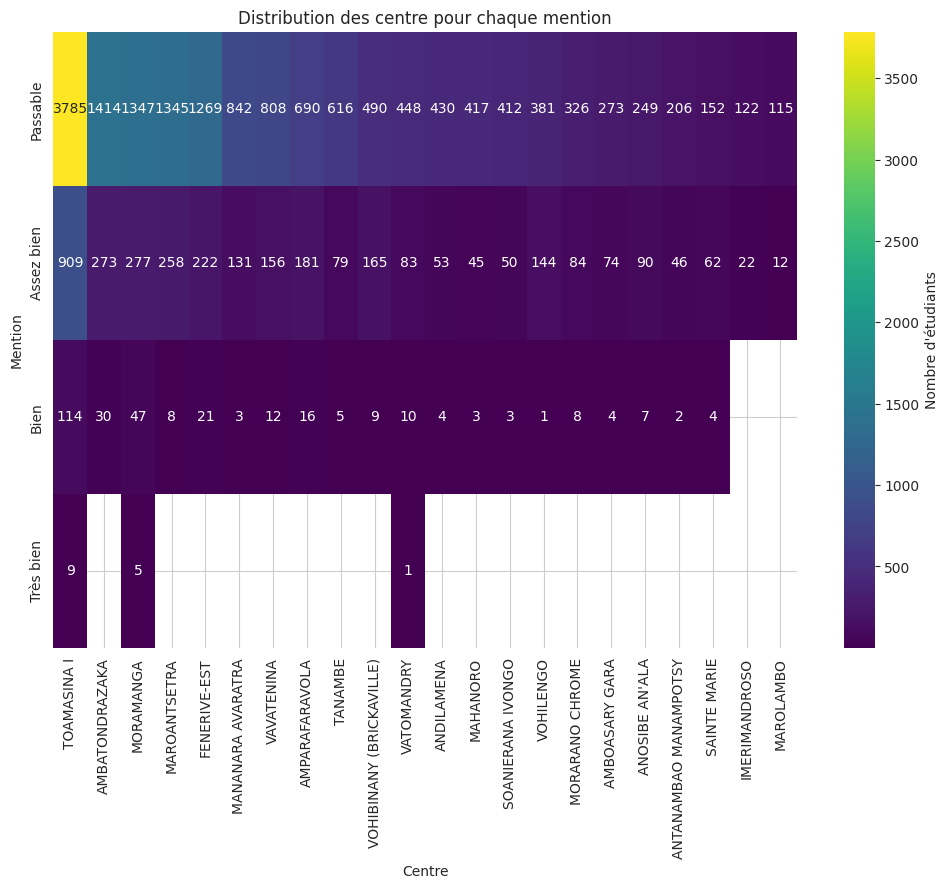

In [ ]:
mentions = data["Mention"].unique()
Centre_mention_counts = []

for mention in mentions:
    subset_data = data[data["Mention"] == mention]
    Centre_counts = subset_data["Centre"].value_counts()
    Centre_mention_counts.append(Centre_counts)

heatmap_data = pd.DataFrame(Centre_mention_counts, index=mentions)

plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, annot=True, cmap="viridis", fmt="g", cbar_kws={'label': 'Nombre d\'étudiants'})
plt.xlabel("Centre")
plt.ylabel("Mention")
plt.title("Distribution des centre pour chaque mention")
plt.show()


>Le tableau représente le nombre d'étudiants dans chaque centre d'examen, classés par mention (Passable, Assez bien, Bien, Très bien). Par exemple, dans le centre d'examen "TOAMASINA I", il y a 3785 étudiants classés "Passable", 909 étudiants classés "Assez bien", 114 étudiants classés "Bien", et 9 étudiants classés "Très bien". Les chiffres fournissent une répartition détaillée des performances des étudiants dans chaque centre selon les différentes mentions.

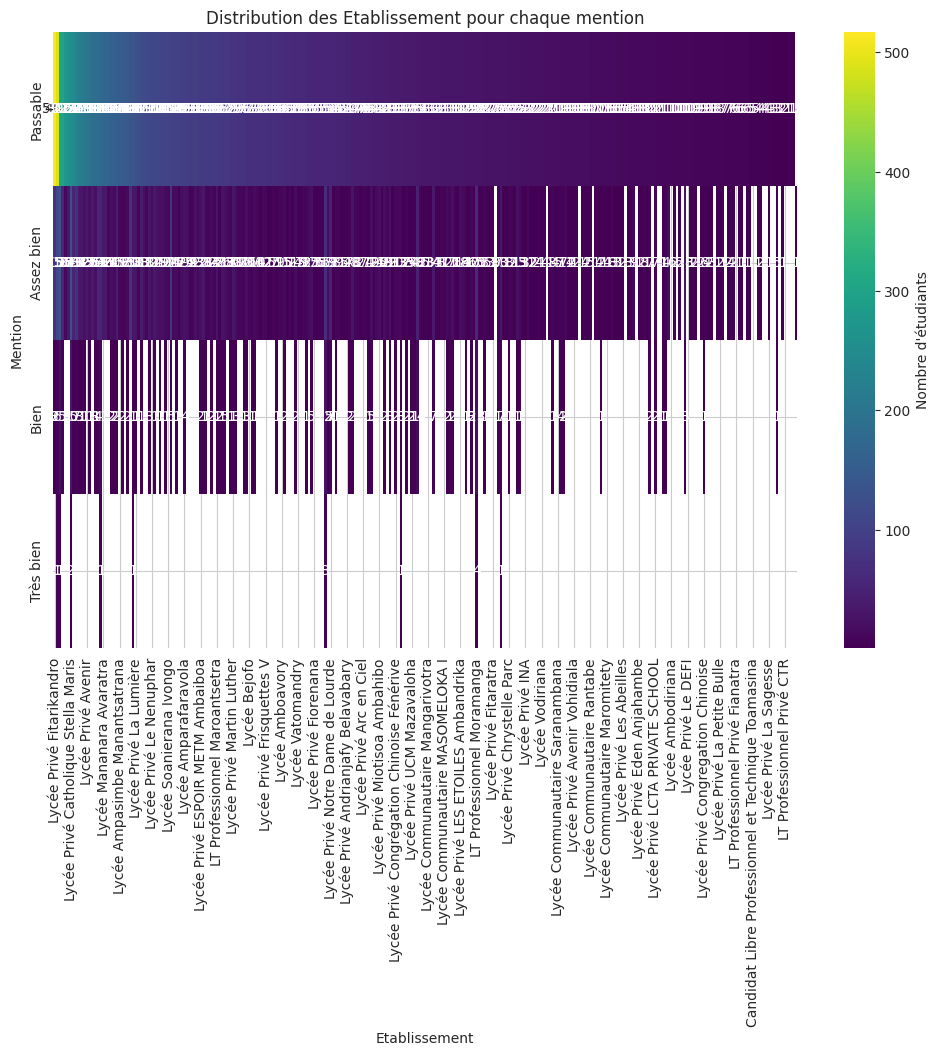

In [ ]:
mentions = data["Mention"].unique()
Etablissement_mention_counts = []

for mention in mentions:
    subset_data = data[data["Mention"] == mention]
    Etablissement_counts = subset_data["Etablissement"].value_counts()
    Etablissement_mention_counts.append(Etablissement_counts)

heatmap_data = pd.DataFrame(Etablissement_mention_counts, index=mentions)

plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, annot=True, cmap="viridis", fmt="g", cbar_kws={'label': 'Nombre d\'étudiants'})
plt.xlabel("Etablissement")
plt.ylabel("Mention")
plt.title("Distribution des Etablissement pour chaque mention")
plt.show()

>Le tableau représente le nombre d'étudiants dans chaque établissement d'examen, classés par mention (Passable, Assez bien, Bien, Très bien). Par exemple, dans le Lycée Privé Fitarikandro, il y a 517 étudiants classés "Passable", 75 étudiants classés "Assez bien", 3 étudiants classés "Bien", et aucun étudiant classé "Très bien". Les chiffres fournissent une répartition détaillée des performances des étudiants dans chaque établissement selon les différentes mentions.

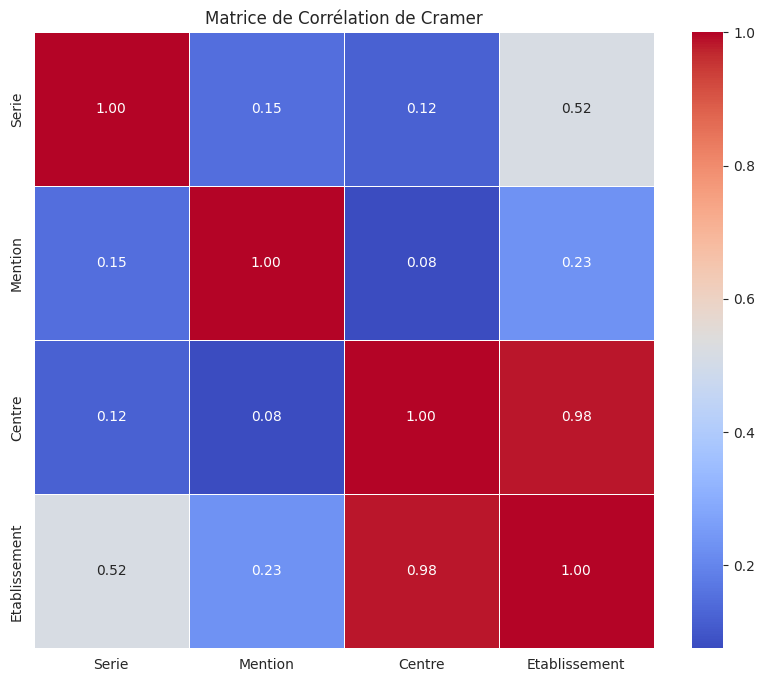

In [ ]:
# Sélectionner les colonnes catégorielles
cat_columns = ['Serie', 'Mention', 'Centre', 'Etablissement']

# Initialiser la matrice de corrélation de Cramer
cramer_matrix = np.zeros((len(cat_columns), len(cat_columns)))

# Calculer le coefficient de corrélation de Cramer pour chaque paire de variables
for i in range(len(cat_columns)):
    for j in range(len(cat_columns)):
        if i != j:
            contingency_table = pd.crosstab(index=data[cat_columns[i]], columns=data[cat_columns[j]])
            chi2, _, _, _ = chi2_contingency(contingency_table)
            n = contingency_table.sum().sum()
            cramers_v = np.sqrt(chi2 / (n * (min(contingency_table.shape) - 1)))
            cramer_matrix[i, j] = cramers_v
        else:
            cramer_matrix[i, j] = 1
# Créer un DataFrame pour afficher la matrice
cramer_df = pd.DataFrame(cramer_matrix, index=cat_columns, columns=cat_columns)

# Afficher la matrice de corrélation de Cramer sous forme de heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(cramer_df, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title('Matrice de Corrélation de Cramer')
plt.show()

In [ ]:
print(cramer_df)

                  Serie   Mention    Centre  Etablissement
Serie          1.000000  0.149182  0.121119       0.518688
Mention        0.149182  1.000000  0.075277       0.227345
Centre         0.121119  0.075277  1.000000       0.983486
Etablissement  0.518688  0.227345  0.983486       1.000000



>La matrice de corrélation de Cramer indique des associations modérées entre la mention et l'établissement (0.23) ainsi qu'une forte liaison entre le centre et l'établissement (0.98), soulignant l'importance potentielle du centre dans la performance des étudiants.

##IV - CONCLUSION
>Dans cette analyse exploratoire de données (AED) du dataset relatif aux résultats du baccalauréat, nous avons entrepris une exploration approfondie des différentes caractéristiques, telles que la série, le centre, et l'établissement. Notre objectif principal, la "mention", a été identifié comme la variable cible pour notre étude. Nous avons constaté que cette variable présentait une faible corrélation avec d'autres caractéristiques, suggérant une relative indépendance. Des étapes de prétraitement ont été nécessaires pour gérer les valeurs manquantes, notamment en fusionnant les colonnes "Nom" et "Prenoms" pour éviter des NaN dans "Prenoms". En utilisant des visualisations telles que les histogrammes et les graphiques de répartition, nous avons exploré la distribution des données. Enfin, la matrice de corrélation de Cramer a été utilisée pour évaluer les relations entre les variables catégorielles, soulignant une indépendance relativement marquée de la "mention". Ces résultats fournissent une base solide pour des analyses plus approfondies et des modélisations futures.

#MOOV ACTU

##I - Introduction
>Dans cette analyse des données de Moov Actu, nous explorons les titres, auteurs, contenus, et dates de publication. L'objectif est de réaliser une Analyse Exploratoire des Données (AED) pour identifier des tendances et corrélations clés, fournissant ainsi des insights approfondis sur la dynamique éditoriale de Moov Actu. Cette approche vise à enrichir notre compréhension du paysage médiatique en mettant en lumière des aspects cruciaux de la diffusion d'informations.
###Variable cible (target): "Genre de l'actualité"
Dans cette analyse exploratoire des données de Moov Actu, notre focalisation est sur la distribution du genre de l'actualité, tel que défini par les catégories spécifiques (Politique, Sport, Culture, etc.). L'objectif premier est de scruter la variabilité de ces genres pour comprendre les préférences des lecteurs et les tendances émergentes. En examinant les auteurs, les titres, les contenus, et les dates de publication, cette approche vise à extraire des insights clés sur les dynamiques éditoriales de Moov Actu, contribuant ainsi à une vision approfondie du paysage médiatique et des intérêts du public.

##II - Importation du Jeu de Données
>Dans cette section, nous procédons à l'importation du jeu de données que nous explorerons par la suite.

In [ ]:
!gdown https://drive.google.com/u/0/uc?id=1-FqKQSdwfAkKzQfd-F36kFUjl-jS9Hui

Downloading...
From: https://drive.google.com/u/0/uc?id=1-FqKQSdwfAkKzQfd-F36kFUjl-jS9Hui
To: /content/moov_actu.csv
100% 696k/696k [00:00<00:00, 31.9MB/s]


In [ ]:
data_original = pd.read_csv('./moov_actu.csv')
data = data_original.copy()
data.head()

,Actu,Auteur,Titre,Date de publication,Contenue
0,Sports,Shar0n,Championat du Monde Foot,14 juin 2018 à 06:55:23 UTC,mba ahoana marina moa raha asiana CHAMPIONAT D...
1,Sports,Shar0n,Football-Can 2019,5 nov. 2018 à 12:00:28 UTC,Ts ay tsony na tetika igafina ny baolina kitra...
2,Sports,rahazahenao,FIARA 2 MITOVY NUMERO D'IMMATRICULATION ETO TANA,18 oct. 2019 à 07:35:28 UTC,"Dia gaga aho ! Zendana aho,talanjona aho nahit..."
3,Sports,Tsitialainga,Ligues des champions,5 févr. 2019 à 08:25:35 UTC,La ligue des champions va reprendre la semaine...
4,Sports,hanitra rakotoniaina,ireny RENAULT MASTER 2 re ve kay?,14 juin 2018 à 06:18:28 UTC,salama daholo hoanareo efa tena mpitaiza fiara...


##III - Exploration et assimilation du jeu des données.
>Au cours de cette phase d'exploration approfondie et d'assimilation des données, nous plongeons au sein du jeu de données, mettant en évidence les caractéristiques essentielles et examinant leur distribution. Cette étape cruciale jettera les fondements nécessaires pour une visualisation significative des tendances qui se dessinent.
###1. Analyse de la Structure

In [ ]:
data.shape

(1608, 5)

- **Lignes :** 1608
- **Colonnes :** 5
- **Types de variables :**
    - Actu : Variable catégorielle (genre de l'actualité).
    - Auteur : Variable catégorielle (auteur de l'article).
    - Titre : Variable catégorielle (titre de l'article).
    - Date de publication : Variable temporelle (date et heure de publication).
    - Contenu : Variable textuelle (contenu de l'article).

- **Analyse des valeurs manquantes :**

In [ ]:
data.isnull().sum()

Actu                   0
Auteur                 0
Titre                  0
Date de publication    0
Contenue               0
dtype: int64

>Heureusement, aucune donnée manquante dans les colonnes Actu, Auteur, Titre, Date de publication et Contenu.

- **Analyse des valeurs dupliqués:**

In [ ]:
data.duplicated().sum()

0

>Encore une bonne nouvelle, pas de doublons

- **Nettoyage des données:**


In [ ]:
data.columns

Index(['Actu', 'Auteur', 'Titre', 'Date de publication', 'Contenue'], dtype='object')

In [ ]:
cols = ['Actu', 'Auteur', 'Titre', 'Contenue']
for col in cols:
    data[col] = data[col].str.lower()
data.sample(10)

,Actu,Auteur,Titre,Date de publication,Contenue
78,sports,non identifi%c3%a9,classico frantsay om psg ce soir 22/10,14 juin 2018 à 06:55:23 UTC,any marseille ny lalaonamoaka didy ny préfet m...
475,sports,non identifi%c3%a9,reniflard_canister,2 mai 2017 à 03:44:00 UTC,"salama daholo,hono ho'aho: aiza re no mba misy..."
785,société,toky,kitrotro,11 déc. 2018 à 08:05:57 UTC,"aminareo , inona no tena antony mampiverina an..."
320,sports,non identifi%c3%a9,etrier arričre citroęn c4,4 avr. 2017 à 10:09:00 UTC,"salama daholo, mba saika hanontany zaho sao di..."
124,sports,non identifi%c3%a9,revision generale,14 juin 2018 à 06:18:28 UTC,"salama daholo nareo,aiza no misy garage afaka ..."
1000,société,non identifi%c3%a9,pédophilie sy ny vokany,4 juil. 2017 à 09:32:00 UTC,"niaran pédophilie aho t@za 5 ans, cousin tezai..."
793,société,non identifi%c3%a9,zaza nisy nanolana,17 juin 2018 à 05:38:04 UTC,"miarahaba antsika rehetra,nisy zaza voaolana k..."
739,société,non identifi%c3%a9,mitady détective privé,14 juin 2018 à 06:22:09 UTC,"salama jiaby,misy afaka mizara contact-na déte..."
1448,société,non identifi%c3%a9,mitady neurologue francais na americain eto mada,14 juin 2018 à 06:22:09 UTC,misy diplomé de france eo fa manaova kely rech...
46,sports,realiste,mpanazatra volamena,14 juin 2018 à 06:55:23 UTC,ny italiana no mitana lohalaharana : bayern :a...


In [ ]:
data['Auteur'] = data['Auteur'].str.replace('%c3%a9', 'e')

data.sample(10)

,Actu,Auteur,Titre,Date de publication,Contenue
1418,société,non identifie,belapin : mi défier ny loi économique universe...,17 juin 2018 à 05:38:04 UTC,amateur-+/ ..zay no azo hifehezana azy :((t@ f...
1322,société,beiapin,fandalovana v ny eto antany sa tsisy tohiny in...,17 juin 2018 à 05:38:04 UTC,mba lazao ny marina hanovana famindra dieny mb...
241,sports,non identifie,mikasa hividy mini-bus mazda inona no tsara ho...,5 févr. 2017 à 19:52:00 UTC,araky ny sujet de mikasa hividy mini-bus mazda...
1171,société,non identifie,lojika malagasy,17 juin 2018 à 05:38:04 UTC,raha hoatra ve misy expert comptable senior mi...
1472,société,non identifie,ceg antanimena itany @ taona 1967 -1968-1969,2 janv. 2017 à 04:22:00 UTC,miarahaba antsika ! mba misy nianatra tao ve? ...
1077,société,non identifie,mitombo ny karazam-pivavahana nefa manaraka an...,17 juin 2018 à 05:38:04 UTC,"mitombo ny karazam-pivavahana, fiangonana nefa..."
475,sports,non identifie,reniflard_canister,2 mai 2017 à 03:44:00 UTC,"salama daholo,hono ho'aho: aiza re no mba misy..."
239,sports,non identifie,mikasika ny ford fiesta 5,9 juil. 2017 à 04:49:00 UTC,ny fahitako azy aloha d tena fiable tokoa. ny ...
1498,by telma,moov_admin,youpi le nouveau site moov c'est bô,14 sept. 2017 à 08:49:34 UTC,qu'en pensez vous ?
747,société,non identifie,misy mahalŕla an'i domoina ve ?,14 juin 2018 à 06:22:09 UTC,"miarahaba antsika rehetra, arak'io lohateny io..."


In [ ]:
mois_fr = ['janv.', 'févr.', 'mars', 'avr.', 'mai', 'juin', 'juil.', 'août', 'sept.', 'oct.', 'nov.', 'déc.']
mois_en = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']

for old, new in zip(mois_fr, mois_en):
    data['Date de publication'] = data['Date de publication'].replace(old, new, regex=True)

In [ ]:
# Convertir la colonne 'Date de publication' en format datetime
data['Date de publication'] = pd.to_datetime(data['Date de publication'], format='%d %b %Y à %H:%M:%S UTC', errors='coerce')

data.head()

,Actu,Auteur,Titre,Date de publication,Contenue
0,sports,shar0n,championat du monde foot,2018-06-14 06:55:23,mba ahoana marina moa raha asiana championat d...
1,sports,shar0n,football-can 2019,2018-11-05 12:00:28,ts ay tsony na tetika igafina ny baolina kitra...
2,sports,rahazahenao,fiara 2 mitovy numero d'immatriculation eto tana,2019-10-18 07:35:28,"dia gaga aho ! zendana aho,talanjona aho nahit..."
3,sports,tsitialainga,ligues des champions,2019-02-05 08:25:35,la ligue des champions va reprendre la semaine...
4,sports,hanitra rakotoniaina,ireny renault master 2 re ve kay?,2018-06-14 06:18:28,salama daholo hoanareo efa tena mpitaiza fiara...


## 2. Analyse de fond
- **Statistiques descriptives :**

In [ ]:
data[cols].describe()

,Actu,Auteur,Titre,Contenue
count,1608,1608,1608,1608
unique,6,101,1578,1599
top,société,non identifie,bizna azo atao any dago,ny mandreraka indraindray dia misy ireo vahiny...
freq,875,1236,2,3


>La présence d'une fréquence de 3 pour le contenu indique qu'il existe des articles identiques répétés trois fois. Par conséquent, pour éviter la redondance et simplifier l'analyse, il serait judicieux de supprimer les doublons basés sur la colonne 'Contenue'.

In [ ]:
data.drop_duplicates(subset='Contenue', inplace=True)
data[cols].describe()

,Actu,Auteur,Titre,Contenue
count,1599,1599,1599,1599
unique,6,101,1575,1599
top,société,non identifie,pédophilie sy ny vokany,mba ahoana marina moa raha asiana championat d...
freq,867,1233,2,1


- **Visualisation des données :**
    - Analyse univariable

In [ ]:
Contenue_list = data['Contenue'].tolist()

Contenue = []
for i in range(len(Contenue_list)):
    liste_mots_sans_ponctuation = [re.sub(r'[^\w\s]', '', mot) for mot in Contenue_list[i].split()]
    Contenue.append(liste_mots_sans_ponctuation)
print(Contenue)

[['mba', 'ahoana', 'marina', 'moa', 'raha', 'asiana', 'championat', 'du', 'monde', 'ny', 'foot', 'e', 'die', 'iza', 'no', 'equipe', 'mety', 'tena', 'ho', 'favorissatria', 'dia', 'samy', 'mpilalao', 'avy', 'ao', 'antanana', 'ihany', 'no', 'antsoinaallemagneespagneangleterreitaliefrance', 'mety', 'ho', 'batainny', 'anglisy', 'foana', 'an', 'ny', 'latino', 'ho', 'eo', 'eo', 'iany', 'fa', 'ny', 'africain', 'de', 'ho', 'velesina', 'fotsiny'], ['ts', 'ay', 'tsony', 'na', 'tetika', 'igafina', 'ny', 'baolina', 'kitra', 'malagasy', 'izao'], ['dia', 'gaga', 'aho', '', 'zendana', 'ahotalanjona', 'aho', 'nahita', 'fiara', '2', 'mitovy', 'marquemtov', 'typemitovy', 'numero', 'saingy', 'ny', 'lokony', 'no', 'samy', 'hafanoheveriko', 'oe', 'nolokoina', 'ilay', 'fiara', 'iray', 't', 'voalohany', 'satria', 'tsy', 'dia', 'mifanalavitra', 'ny', 'toerana', 'misy', 'azy', 'ireohay', 'ka', 'tena', 'fiara', 'hafa', 'mihitsy', 'ity', 'hitako', 'faharoa', 'satria', 'vao', 'avy', 'nahita', 'ilay', '1', 'aho', '

>Le code prend la colonne 'contenue' d'un ensemble de données (probablement un DataFrame) et crée une nouvelle liste appelée 'Contenue', où chaque élément de la liste correspond à la 'contenue' originale, mais chaque mot est dépourvu de ponctuation. Cela est réalisé en divisant chaque 'contenue' en mots et en retirant la ponctuation de chaque mot. La liste résultante, 'Contenue', est une liste de listes, où chaque sous-liste contient les mots d'une 'contenue' sans ponctuation.

In [ ]:
data['Contenue_list'] = Contenue

In [ ]:
mots_concatenes = [mot for liste in Contenue for mot in liste]

compteur_mots = Counter(mots_concatenes)

mot_plus_frequent = compteur_mots.most_common()

In [ ]:
mot_plus_frequent[:10]

[('ny', 4357),
 ('tsy', 1937),
 ('', 1744),
 ('dia', 1697),
 ('fa', 1641),
 ('no', 1515),
 ('misy', 849),
 ('sy', 796),
 ('de', 790),
 ('mba', 735)]

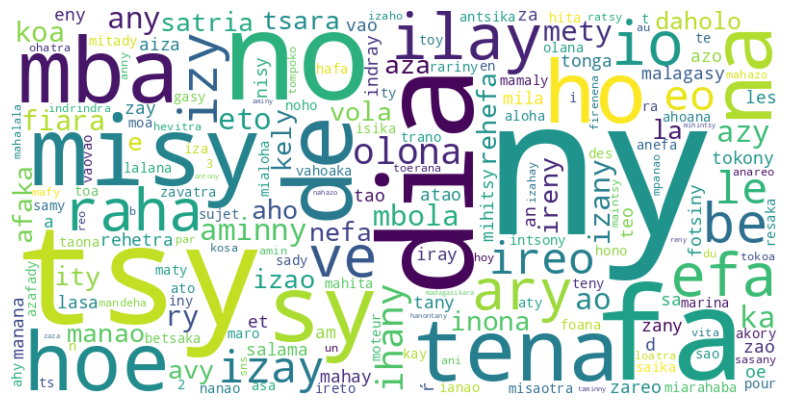

In [ ]:
data_dict = dict(mot_plus_frequent)

# Utiliser WordCloud pour générer un nuage de mots
wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(data_dict)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

>La liste fournie représente les mots les plus fréquemment rencontrés dans le texte, avec 'ny' comme le plus fréquent. Certains éléments, comme le mot vide (''), pourraient nécessiter une attention particulière lors du nettoyage du texte.

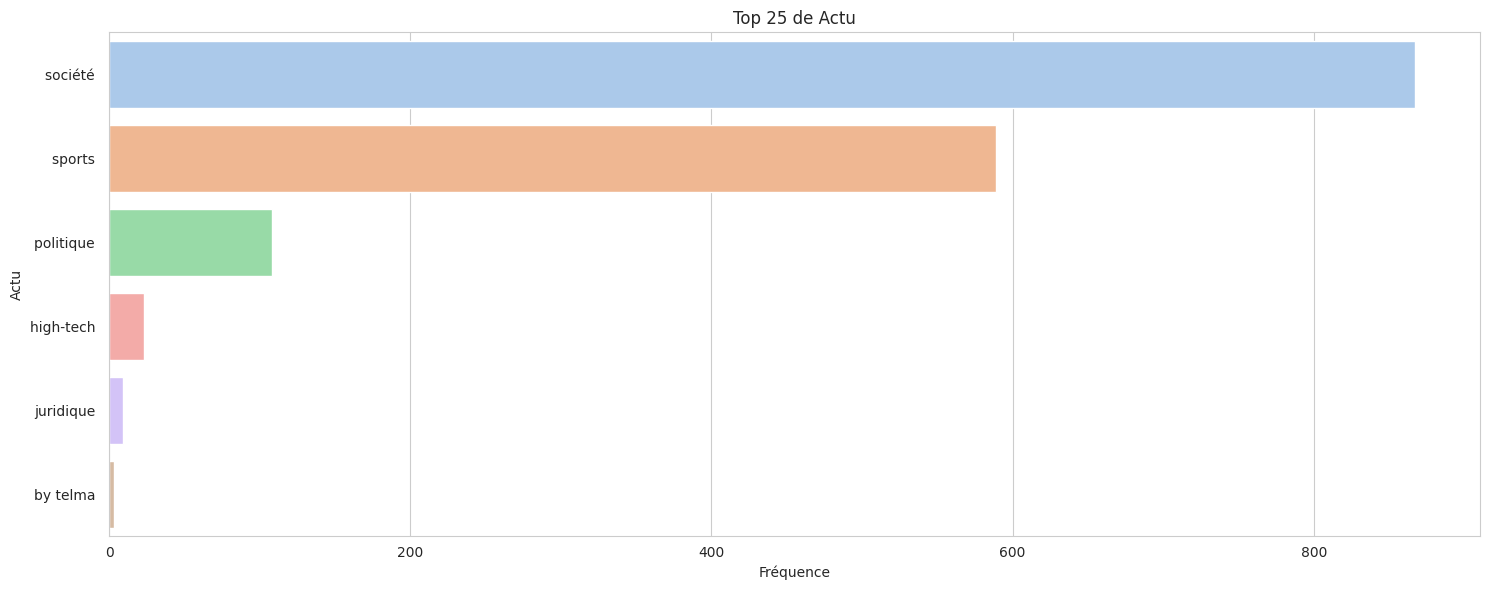

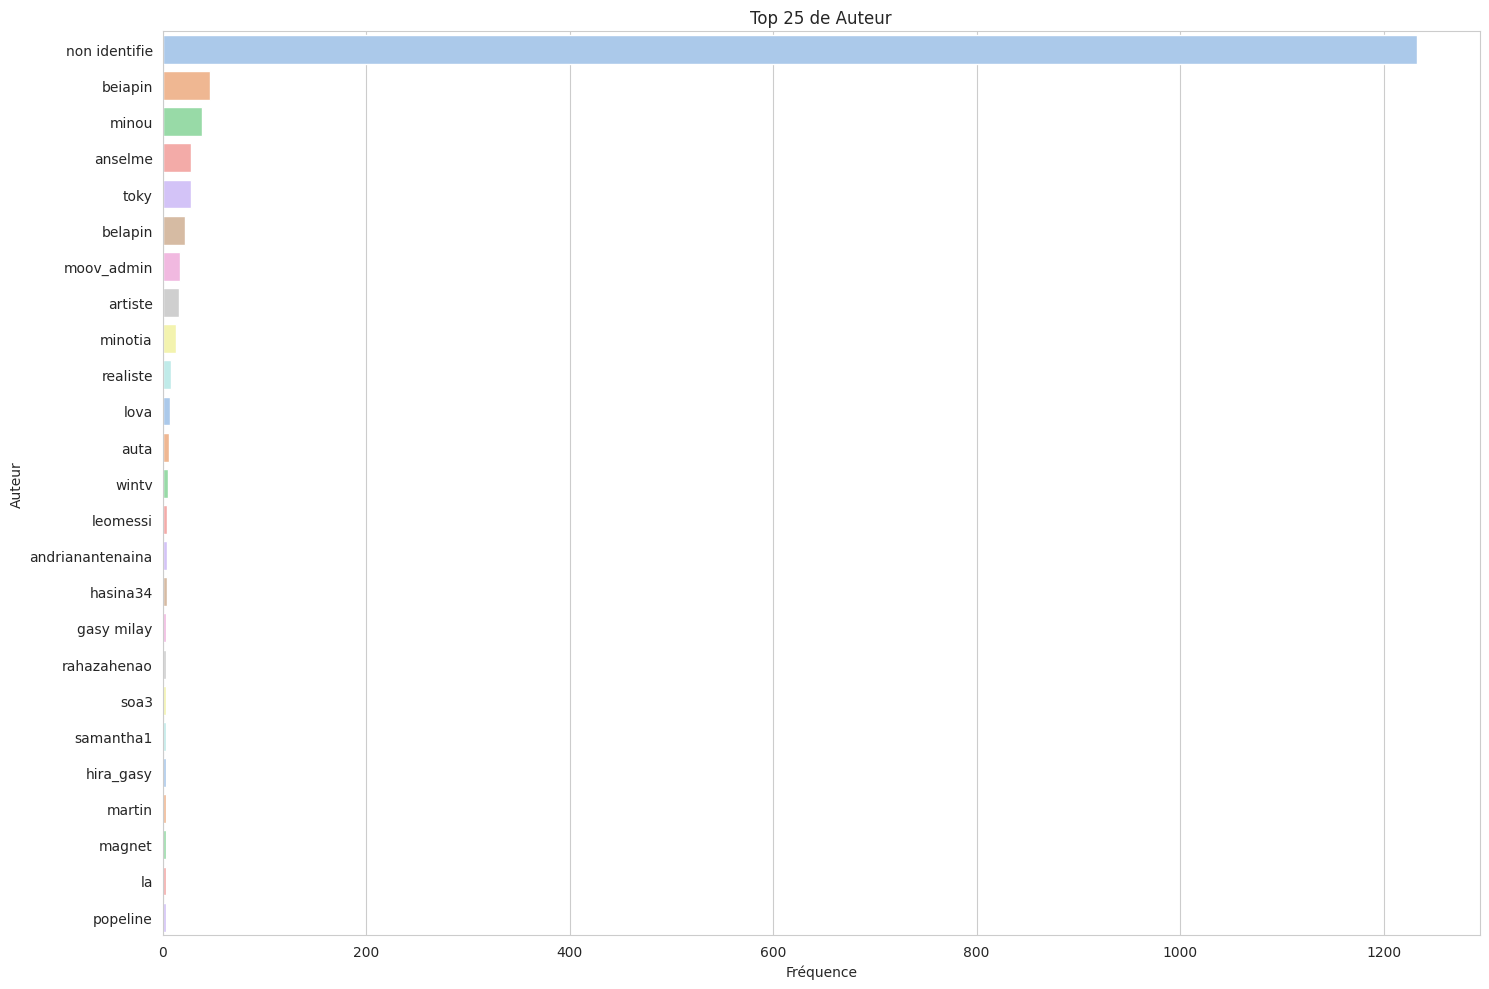

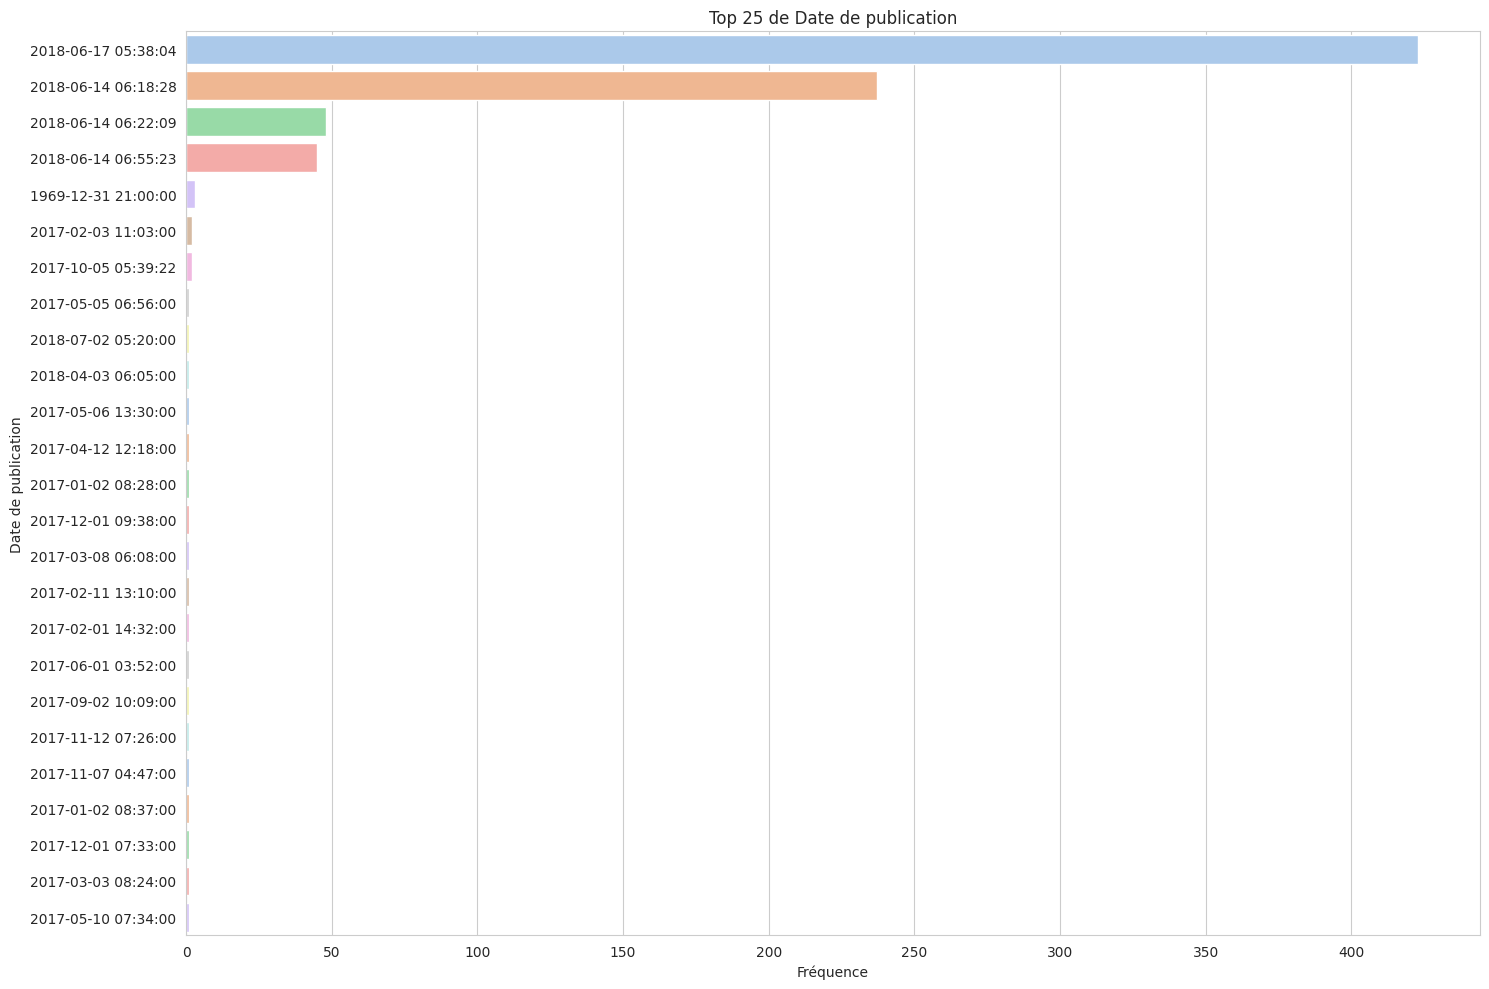

In [ ]:
warnings.filterwarnings("ignore", category=UserWarning)

for col in data.columns:
    if col != 'Titre' and col != 'Contenue' and col!= 'Contenue_list':
        size = data[col].nunique()
        top = 25
        if size > 10:
            size = 10
        plt.figure(figsize=(15, size))
        sns.countplot(y=col, data=data, palette='pastel', order=data[col].value_counts().index[:top])
        plt.title(f'Top {top} de {col}')
        plt.xlabel('Fréquence')
        plt.ylabel(col)
        plt.tight_layout()
        plt.show()
        print('\n')

> - Graphe 1: Fréquence des Catégories "Actu"

Le premier graphique révèle que la catégorie "Société" compte 875 articles, suivie de "Sports" avec 589 articles, "Politique" avec 108 articles, "High-tech" avec 23 articles, "Juridique" avec 10 articles, et "By Telma" avec 3 articles. Cela suggère une diversité d'articles répartis entre différentes catégories d'actualités.
> - Graphe 2: Fréquence des Auteurs

Le deuxième graphique indique que la plupart des articles (1236) sont attribués à des auteurs non identifiés. Les autres auteurs, tels que "Beiapin", "Minou", "Anselme", et "Toky", ont des fréquences inférieures mais contribuent également à la variété des contributeurs.
> - Graphe 3: Fréquence des Dates de Publication

Le troisième graphique montre que la date la plus fréquente de publication est "2018-06-17 05:38:04" avec 426 articles, suivie de "2018-06-14 06:18:28" avec 237 articles. Cependant, il est important de noter que la date "1969-12-31 21:00:00" apparaît plusieurs fois, ce qui pourrait indiquer des valeurs manquantes ou des anomalies dans la collecte des données.

- ** **
    
    - Analyse Bivariable

<Figure size 1200x800 with 0 Axes>

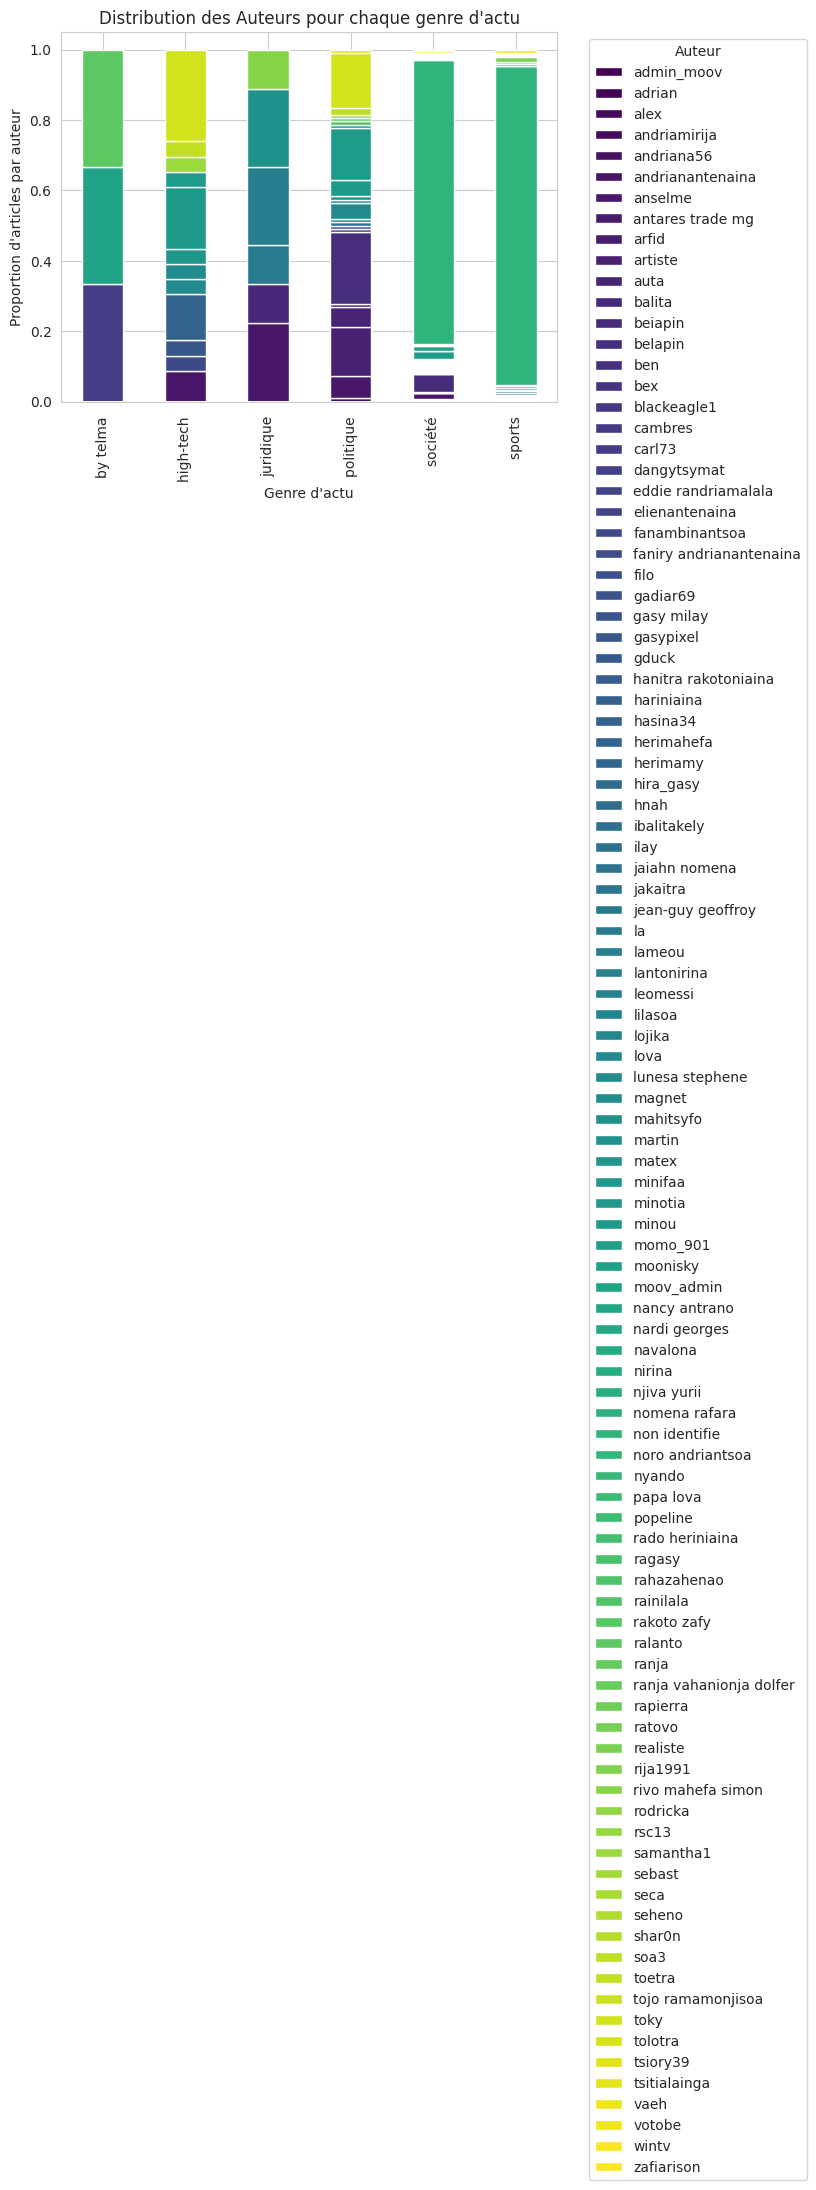

In [ ]:
grouped_data = data.groupby(["Actu", "Auteur"]).size().unstack(fill_value=0)

# Normaliser les données pour obtenir des proportions au lieu de comptages
normalized_data = grouped_data.div(grouped_data.sum(axis=1), axis=0)

plt.figure(figsize=(12, 8))
normalized_data.plot(kind='bar', stacked=True, cmap="viridis")
plt.xlabel("Genre d'actu")
plt.ylabel("Proportion d'articles par auteur")
plt.title("Distribution des Auteurs pour chaque genre d'actu")
plt.legend(title="Auteur", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

>Ce tableau analyse la distribution des contributions d'auteurs à différentes catégories d'actualités. Les auteurs tels qu'Admin_Moov, Adrian, Alex ont une contribution généralement faible dans toutes les catégories. Anselme se distingue avec une forte implication dans "Juridique", ainsi que des contributions notables dans "Politique" et "Société". En revanche, Antares Trade MG, Arfid, et Artiste présentent des contributions limitées. Certains auteurs, tels que Toky, Tsiory39, et Tsitialainga, se démarquent particulièrement dans la catégorie "Sports", avec Toky montrant également une influence notable dans "High-tech". En somme, cette analyse souligne la diversité des contributions des auteurs, mettant en lumière des tendances spécifiques à chaque catégorie d'actualité.

<Figure size 1200x800 with 0 Axes>

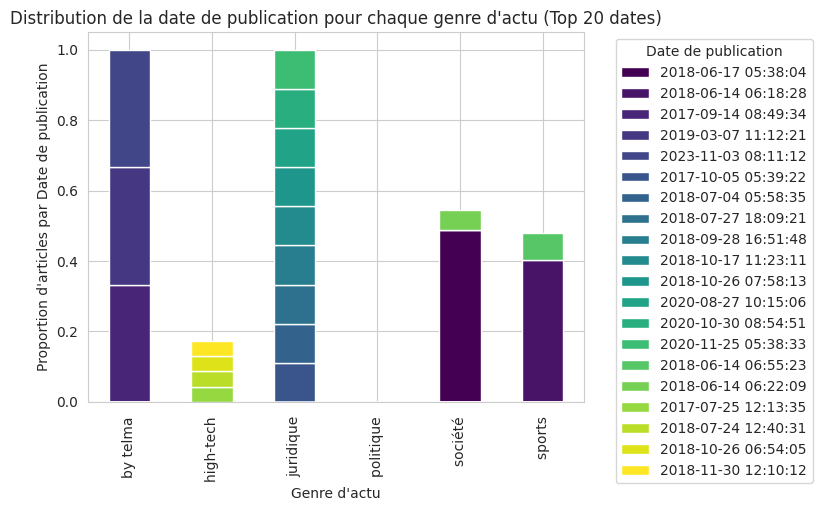

In [ ]:
grouped_data = data.groupby(["Actu", "Date de publication"]).size().unstack(fill_value=0)

# Normaliser les données pour obtenir des proportions au lieu de comptages
normalized_data = grouped_data.div(grouped_data.sum(axis=1), axis=0)

# Trier les colonnes par ordre décroissant des proportions
normalized_data = normalized_data[sorted(normalized_data.columns, key=lambda x: normalized_data[x].sum(), reverse=True)]

# Sélectionner les 20 principales colonnes
top_20_dates = normalized_data.iloc[:, :20]

plt.figure(figsize=(12, 8))
top_20_dates.plot(kind='bar', stacked=True, cmap="viridis")
plt.xlabel("Genre d'actu")
plt.ylabel("Proportion d'articles par Date de publication")
plt.title("Distribution de la date de publication pour chaque genre d'actu (Top 20 dates)")
plt.legend(title="Date de publication", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()


>Ce tableau présente la distribution proportionnelle des articles pour chaque genre d'actualité en fonction de différentes dates de publication. Quelques observations clés incluent la prédominance de la catégorie "Société" le 17 juin 2018, une diversité d'articles dans les catégories "Société" et "Sports" le 14 juin 2018, une répartition équitable entre plusieurs catégories le 3 novembre 2023, et des contributions significatives dans la catégorie "Juridique" à certaines dates comme le 5 octobre 2017. Ces variations reflètent des tendances éditoriales ou des événements spécifiques associés à chaque jour de publication, offrant un aperçu de la dynamique évolutive des sujets d'actualité au fil du temps.

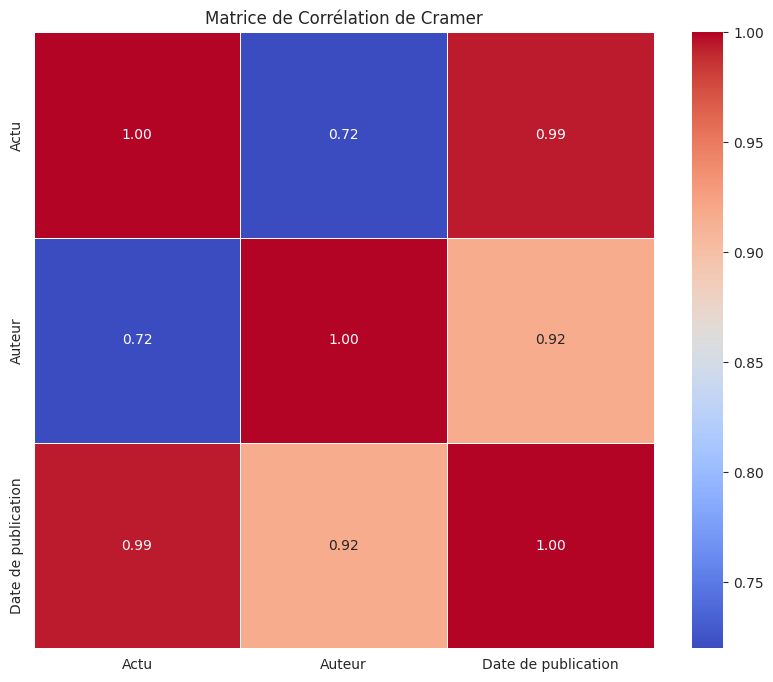

In [ ]:
# Sélectionner les colonnes catégorielles
cat_columns = ['Actu', 'Auteur', 'Date de publication']

# Initialiser la matrice de corrélation de Cramer
cramer_matrix = np.zeros((len(cat_columns), len(cat_columns)))

# Calculer le coefficient de corrélation de Cramer pour chaque paire de variables
for i in range(len(cat_columns)):
    for j in range(len(cat_columns)):
        if i != j:
            contingency_table = pd.crosstab(index=data[cat_columns[i]], columns=data[cat_columns[j]])
            chi2, _, _, _ = chi2_contingency(contingency_table)
            n = contingency_table.sum().sum()
            cramers_v = np.sqrt(chi2 / (n * (min(contingency_table.shape) - 1)))
            cramer_matrix[i, j] = cramers_v
        else:
            cramer_matrix[i, j] = 1
# Créer un DataFrame pour afficher la matrice
cramer_df = pd.DataFrame(cramer_matrix, index=cat_columns, columns=cat_columns)

# Afficher la matrice de corrélation de Cramer sous forme de heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(cramer_df, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title('Matrice de Corrélation de Cramer')
plt.show()

In [ ]:
print(cramer_df)

                         Actu    Auteur  Date de publication
Actu                 1.000000  0.719854             0.994371
Auteur               0.719854  1.000000             0.916711
Date de publication  0.994371  0.916711             1.000000


>La matrice de corrélation indique une corrélation modérée entre les catégories "Actu" et "Auteur" (0.72), une forte corrélation entre "Actu" et "Date de publication" (0.99), ainsi qu'une corrélation forte entre "Auteur" et "Date de publication" (0.92). Cela suggère des variations cohérentes entre ces variables, avec une forte association entre "Actu" et "Date de publication".

##IV - CONCLUSION
>
L'analyse des données montre une forte corrélation entre la catégorie "Actu" et la date de publication, suggérant une tendance à la couverture de certains sujets à des moments spécifiques. Cependant, des erreurs ont été rencontrées lors de la visualisation de la fréquence des mots par catégorie. Malgré ces obstacles, la corrélation élevée souligne l'importance de la temporalité dans la couverture des actualités. Une exploration plus approfondie et la résolution des problèmes techniques pourraient fournir des informations plus détaillées.

#ORANGE ACTU


##I - Introduction
>Dans cette analyse des données de l'Orange Actu, nous entreprenons une Exploration des Données (EDA) afin de dévoiler les nuances cachées dans les titres, auteurs, contenus et dates de publication. L'objectif principal est de conduire une analyse approfondie des dynamiques éditoriales de l'Orange Actu, révélant des tendances significatives et des corrélations essentielles. Cette démarche vise à élargir notre compréhension du paysage médiatique en mettant en lumière des facettes cruciales de la diffusion d'informations au sein de cette plateforme d'actualités.

##II - Importation du Jeu de Données
>Dans cette section, nous procédons à l'importation du jeu de données que nous explorerons par la suite.

In [ ]:
!gdown https://drive.google.com/u/0/uc?id=1-A3UgbnDeRJiy5FrZjTzYjdiEuzetYcp

Downloading...
From: https://drive.google.com/u/0/uc?id=1-A3UgbnDeRJiy5FrZjTzYjdiEuzetYcp
To: /content/orange_actu.csv
100% 41.4M/41.4M [00:00<00:00, 98.4MB/s]


In [ ]:
data_original = pd.read_csv('./orange_actu.csv')
data = data_original.copy()
data.head()

,titre,contenue,dataPublication
0,COLLECTIF DES CANDIDATS,Les 11 candidats n'acceptent pas la date de l'...,1.697898e+12
1,AGENCE JIRAMA ANKAZOMANGA,L'Agence Jirama à Ankazomanga déménage à Ambod...,1.697900e+12
2,NECROLOGIE,"L'auteur, compositeur et interprète malgache A...",1.697904e+12
3,ANDRY RAJOELINA,Andry Rajoelina a repris sa tournée régionale ...,1.697908e+12
4,AFFAIRE RAZAFINDREMAKA THOMAS,"59 mouvements, plateformes, coalitions, collec...",1.697951e+12



## III - Exploration et Assimilation du Jeu de Données
>Pendant cette phase d'exploration approfondie et d'assimilation des données relatives à l'Orange Actu, nous nous plongeons dans le jeu de données afin de mettre en évidence les caractéristiques essentielles et d'examiner leur distribution. Cette étape cruciale jettera les bases nécessaires à une visualisation significative des tendances émergentes et des dynamiques propres à l'actualité sur la plateforme.

###1. Analyse de la Structure des Données

In [ ]:
data.shape

(93442, 3)

- **Lignes :** 93442
- **Colonnes :** 3
- **Types de variables :**
    - Titre : Variable catégorielle (titre de l'article).
    - Contenu : Variable textuelle (contenu de l'article).
    - Date de publication : Variable temporelle (date et heure de publication).

- **Analyse des valeurs manquantes :**

In [ ]:
data.isnull().sum()

titre               0
contenue            0
dataPublication    30
dtype: int64

>Heureusement, on a que 30 donnée manquante dans les colonnes dataPublication.

In [ ]:
data.dropna(subset='dataPublication', inplace=True)

- **Analyse des valeurs dupliqués:**

In [ ]:
data.duplicated().sum()

0

>Encore une bonne nouvelle, pas de doublons

- **Nettoyage des données:**

In [ ]:
cols = ['titre', 'contenue']
for col in cols:
    data[col] = data[col].str.lower()


>Ce code convertit en minuscules ('lowercase') les valeurs des colonnes 'titre' et 'contenue' du DataFrame data et affiche un échantillon de 10 lignes.

In [ ]:
from datetime import datetime
def convert_timestamp(timestamp):
    try:
        # Vérifier si le timestamp est dans une plage raisonnable
        if 0 < timestamp/1000 < 2**31:
            dt_object = datetime.utcfromtimestamp(timestamp)
            return dt_object
        else:
            return None  # Retourner None pour les valeurs de timestamp impossibles
    except ValueError as e:
        print(f"Erreur lors de la conversion du timestamp : {e}")
        return None
date = []
for timestamp in data['dataPublication']:
    converted_time = convert_timestamp(timestamp/1000)
    if converted_time is not None:
        date.append(converted_time)
    else:
        data.drop(data[data['dataPublication'] == timestamp].index, inplace=True)

>Le code convertit les timestamps en millisecondes dans la colonne 'dataPublication' d'un DataFrame en objets datetime, les ajoute à une liste appelée 'date'. Les lignes correspondant aux timestamps impossibles ou hors de la plage raisonnable sont supprimées du DataFrame.

In [ ]:
data['date de publication'] = date
data.drop('dataPublication', axis=1, inplace=True)

>La ligne de code ci-dessus prend chaque timestamp dans la colonne 'dataPublication', convertit ces timestamps en dates (en supprimant ceux qui sont impossibles), puis crée une nouvelle colonne 'date de publication' avec ces dates. Enfin, elle supprime la colonne 'dataPublication'.

In [ ]:
data.head()

,titre,contenue,date de publication
0,collectif des candidats,les 11 candidats n'acceptent pas la date de l'...,2023-10-21 14:26:00
1,agence jirama ankazomanga,l'agence jirama à ankazomanga déménage à ambod...,2023-10-21 15:00:00
2,necrologie,"l'auteur, compositeur et interprète malgache a...",2023-10-21 16:00:00
3,andry rajoelina,andry rajoelina a repris sa tournée régionale ...,2023-10-21 17:00:00
4,affaire razafindremaka thomas,"59 mouvements, plateformes, coalitions, collec...",2023-10-22 05:00:00


## 2. Analyse de fond
- **Statistiques descriptives :**

In [ ]:
data[cols].describe()

,titre,contenue
count,93410,93410
unique,30260,91827
top,mahajanga,pour suivre les informations en temps réel 24/...
freq,938,44


>Les colonnes 'titre' et 'contenue' contiennent des informations sur 93 410 éléments. Cependant, la colonne 'contenue' présente des duplicatas (91 827 uniques), suggérant la possibilité de nettoyer les données en supprimant les doublons.

In [ ]:
data.drop_duplicates(subset='contenue', inplace=True)
data[cols].describe()

,titre,contenue
count,91827,91827
unique,29959,91827
top,mahajanga,les 11 candidats n'acceptent pas la date de l'...
freq,936,1


- **Visualisation des données :**
    - Analyse univariable

In [ ]:
nltk.download('stopwords')
nltk.download('punkt')

stop_words = set(stopwords.words('french'))
Contenue_list = data['contenue'].tolist()
Contenue = []
for i in range(len(Contenue_list)):
    liste_mots_sans_ponctuation_et_stopwords = [re.sub(r'[^\w\s]', '', mot) for mot in Contenue_list[i].split() if mot.lower() not in stop_words]
    Contenue.append(liste_mots_sans_ponctuation_et_stopwords)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!



>Le code prend la colonne 'contenue' d'un ensemble de données (probablement un DataFrame) et crée une nouvelle liste appelée 'Contenue', où chaque élément de la liste correspond à la 'contenue' originale, mais chaque mot est dépourvu de ponctuation. Cela est réalisé en divisant chaque 'contenue' en mots et en retirant la ponctuation de chaque mot. La liste résultante, 'Contenue', est une liste de listes, où chaque sous-liste contient les mots d'une 'contenue' sans ponctuation.

In [ ]:
data['contenue_list'] = Contenue

In [ ]:
mots_concatenes = [mot for liste in Contenue for mot in liste]
compteur_mots = Counter(mots_concatenes)
mot_plus_frequent = compteur_mots.most_common()

>Ces lignes de code créent une liste appelée 'mots_concatenes', qui contient tous les mots extraits des listes de mots dans la liste 'Contenue'. Ensuite, elles utilisent la classe Counter pour compter la fréquence de chaque mot dans 'mots_concatenes'. Enfin, la variable 'mot_plus_frequent' contient le mot le plus fréquent ainsi que son nombre d'occurrences, et ce, sous la forme d'un tuple.

In [ ]:
mot_plus_frequent[:10]

[('a', 59950),
 ('madagascar', 34421),
 ('', 26213),
 ('cette', 22094),
 ('nationale', 13240),
 ('ministère', 12591),
 ('plus', 12281),
 ('ainsi', 12004),
 ('président', 9229),
 ('selon', 9166)]

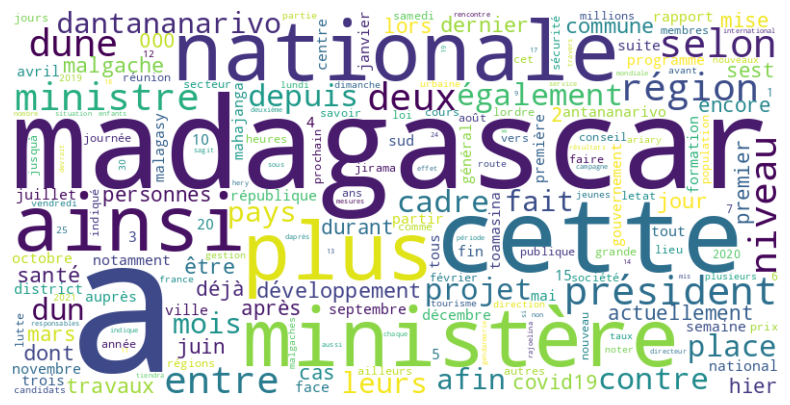

In [ ]:
data_dict = dict(mot_plus_frequent)
wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(data_dict)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

>Les mots les plus fréquents dans le contenu sont "madagascar", "cette", "nationale", "ministère", "plus", "ainsi", "président", et "selon", avec leurs occurrences respectives de 34421, 22094, 13240, 12591, 12281, 12004, 9229, et 9166.

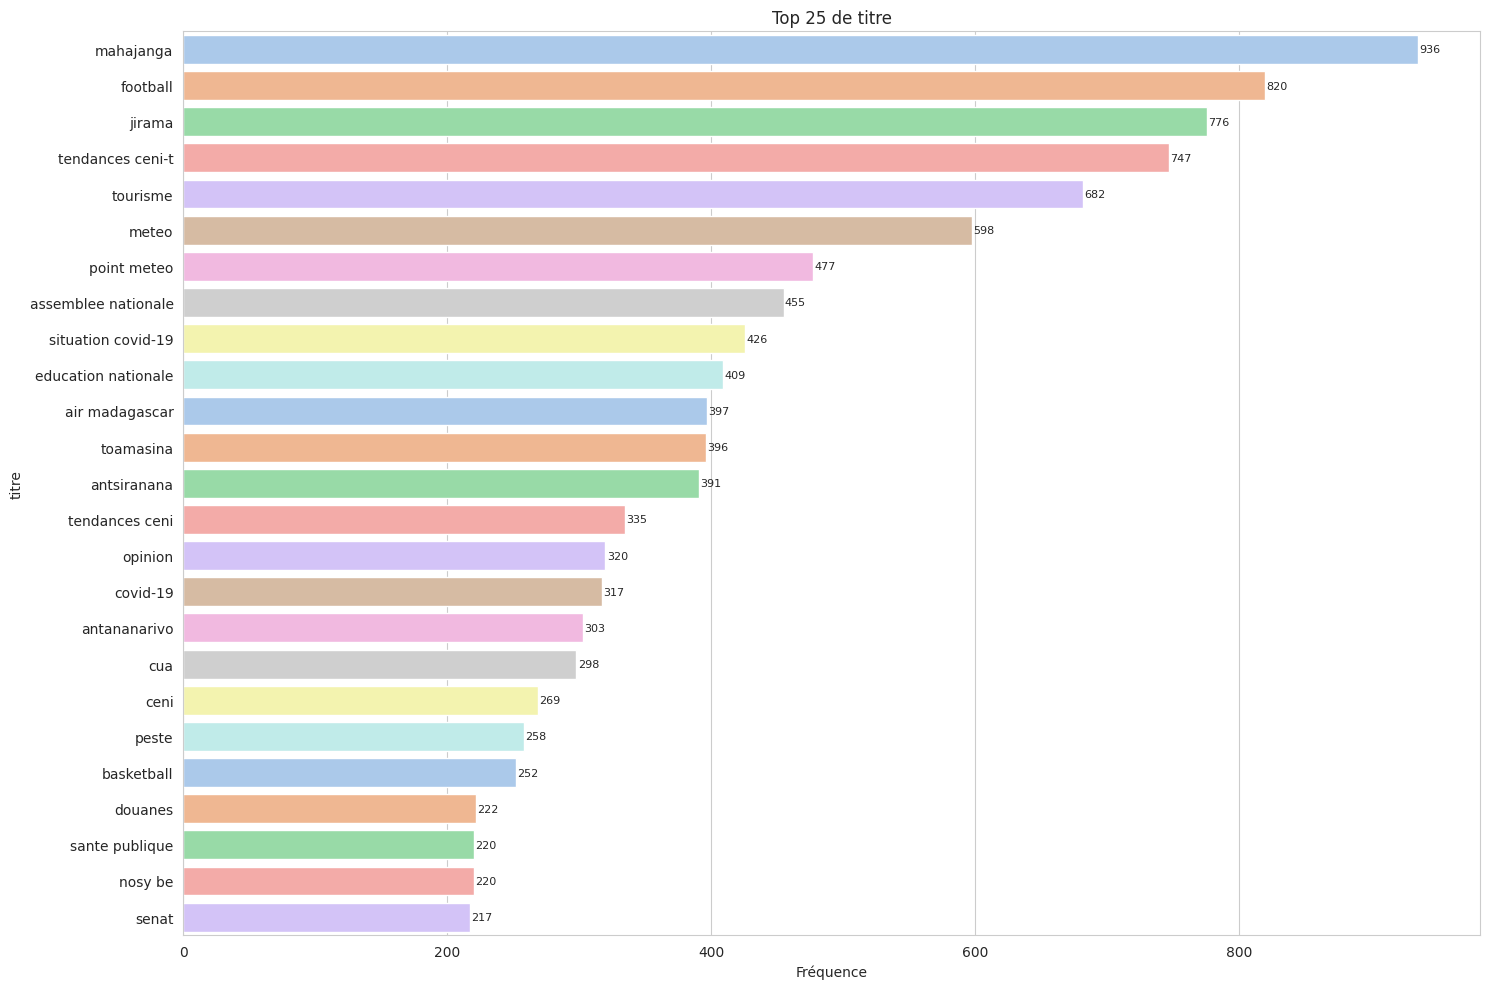

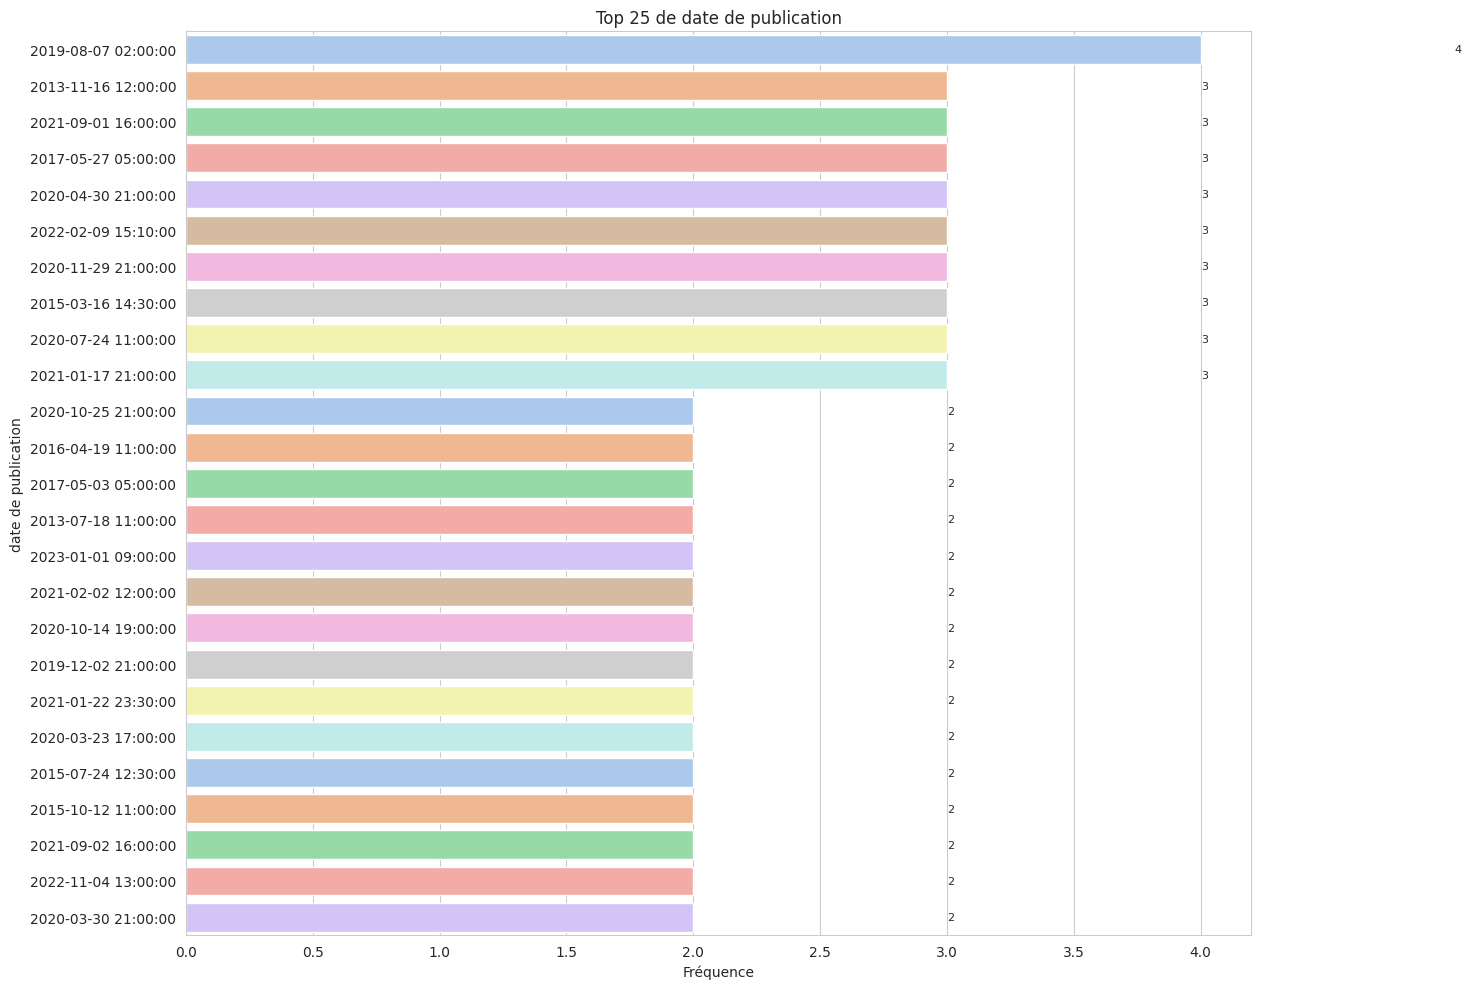

In [ ]:
warnings.filterwarnings("ignore", category=UserWarning)

for col in data.columns:
    if col != 'contenue' and col!= 'contenue_list':
        size = data[col].nunique()
        top = 25
        if size > 10:
            size = 10
        plt.figure(figsize=(15, size))
        sns.countplot(y=col, data=data, palette='pastel', order=data[col].value_counts().index[:top])
        for i, v in enumerate(data[col].value_counts()[:top]):
            plt.text(v + 1, i, str(v), ha='left', va='center', fontsize=8)
        plt.title(f'Top {top} de {col}')
        plt.xlabel('Fréquence')
        plt.ylabel(col)
        plt.tight_layout()
        plt.show()
        print('\n')

> - Graphe 1: Fréquence des Catégories "titre"

Le premier graphique révèle que la catégorie "Mahajanga" compte 936 articles, suivie de "football" avec 820 articles, et ainsi de suite.

> - Graphe 2: Fréquence des Dates de Publication

Le troisième graphique montre que la date la plus fréquente de publication est "2019-08-07 02:00:00" avec 4 articles, suivie de "2013-11-16 12:00:00" avec 3 articles, et ainsi de suite.


##IV - CONCLUSION
>Au cours de cette analyse de données, j'ai traité les timestamps, converti les valeurs en dates, supprimé les valeurs aberrantes, et transformé le texte en minuscules. J'ai également exploré la distribution des données, identifié les doublons de contenu et nettoyé le texte en retirant la ponctuation. Enfin, j'ai extrait les mots les plus fréquents, éliminé les stopwords, et visualisé les tendances des données à l'aide de graphiques. Cette approche complète a permis d'obtenir des insights significatifs et de préparer les données pour des analyses plus avancées.

#MIDI ACTU

In [ ]:
!gdown https://drive.google.com/u/0/uc?id=1h_1GZIsZF0pvLl7sNlqe_Du6G_monFNp

Downloading...
From: https://drive.google.com/u/0/uc?id=1h_1GZIsZF0pvLl7sNlqe_Du6G_monFNp
To: /content/midi.csv
100% 3.00M/3.00M [00:00<00:00, 147MB/s]


In [ ]:
import dataprep